In [33]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Library

In [34]:
import pandas as pd
import numpy as np


## 2. Load Dataset

In [35]:
df = pd.read_csv("/content/drive/MyDrive/smart_classroom.csv")
df.head()

,timestamp,indoor_temp_c,indoor_humidity_pct,outdoor_temp_c,outdoor_humidity_pct,day_period,ac_setpoint_c
0,2026-11-02 08:00:00,26.45,64.51,26.68,74.79,Morning,27.0
1,2026-11-02 08:05:00,26.53,64.17,26.67,74.96,Morning,27.0
2,2026-11-02 08:10:00,26.56,64.71,26.73,75.24,Morning,27.0
3,2026-11-02 08:15:00,26.56,64.68,26.96,74.06,Morning,27.0
4,2026-11-02 08:20:00,26.05,64.64,26.79,74.24,Morning,27.0


## 3. Explore Dataset

In [36]:
# Dataset information
print("Dataset Shape:", df.shape)
print("=========================")

# Column information
print("\nDataset Information:")
df.info()
print("=========================")

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())
print("=========================")

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())
print("=========================")

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (327, 7)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 327 entries, 0 to 326
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   timestamp             327 non-null    object 
 1   indoor_temp_c         327 non-null    float64
 2   indoor_humidity_pct   327 non-null    float64
 3   outdoor_temp_c        327 non-null    float64
 4   outdoor_humidity_pct  327 non-null    float64
 5   day_period            327 non-null    object 
 6   ac_setpoint_c         327 non-null    float64
dtypes: float64(5), object(2)
memory usage: 18.0+ KB

Missing Values:
timestamp               0
indoor_temp_c           0
indoor_humidity_pct     0
outdoor_temp_c          0
outdoor_humidity_pct    0
day_period              0
ac_setpoint_c           0
dtype: int64

Statistical Summary:


,indoor_temp_c,indoor_humidity_pct,outdoor_temp_c,outdoor_humidity_pct,ac_setpoint_c
count,327.000000,327.000000,327.000000,327.000000,327.000000
mean,23.466086,71.691529,29.496453,71.467125,25.487768
std,1.298188,2.356753,2.024263,8.022248,1.752694
min,21.870000,64.170000,25.360000,54.080000,22.000000
25%,22.555000,70.050000,28.095000,66.715000,24.500000
50%,23.180000,71.650000,29.300000,72.930000,26.000000
75%,23.885000,73.195000,30.895000,77.835000,26.500000
max,27.900000,77.950000,33.390000,84.260000,29.000000



Duplicate Rows: 0


In [37]:
# Check distribution of target variable
print(df["ac_setpoint_c"].value_counts().sort_index())

# Check target statistics
print(df["ac_setpoint_c"].describe())

# Check correlation with target
print(df.corr(numeric_only=True)["ac_setpoint_c"].sort_values(ascending=False))

# Compare training and testing target distributions
print("\nTraining target:")
print(y_train.describe())

print("\nTesting target:")
print(y_test.describe())

ac_setpoint_c
22.0    28
22.5    20
24.0     8
24.5    38
25.0    52
26.0    46
26.5    70
27.0    38
27.5     4
28.5    17
29.0     6
Name: count, dtype: int64
count    327.000000
mean      25.487768
std        1.752694
min       22.000000
25%       24.500000
50%       26.000000
75%       26.500000
max       29.000000
Name: ac_setpoint_c, dtype: float64
ac_setpoint_c           1.000000
outdoor_temp_c          0.266207
indoor_temp_c           0.089213
outdoor_humidity_pct   -0.156189
indoor_humidity_pct    -0.379742
Name: ac_setpoint_c, dtype: float64

Training target:
count    261.000000
mean      25.260536
std        1.824284
min       22.000000
25%       24.500000
50%       25.000000
75%       26.500000
max       29.000000
Name: ac_setpoint_c, dtype: float64

Testing target:
count    66.000000
mean     26.386364
std       1.033275
min      24.500000
25%      26.500000
50%      26.500000
75%      26.500000
max      28.500000
Name: ac_setpoint_c, dtype: float64


## 4. Preprocess the data

In [38]:
# Convert timestamp into datetime
df["timestamp"] = pd.to_datetime(df["timestamp"])

# Extract hour and minute
df["hour"] = df["timestamp"].dt.hour
df["minute"] = df["timestamp"].dt.minute

# Convert day_period into numerical values
df["day_period"] = df["day_period"].map({
    "Morning": 0,
    "Afternoon": 1,
    "Evening": 2
})

# Drop original timestamp
df = df.drop(columns=["timestamp"])

# Check processed data
df.head()

,indoor_temp_c,indoor_humidity_pct,outdoor_temp_c,outdoor_humidity_pct,day_period,ac_setpoint_c,hour,minute
0,26.45,64.51,26.68,74.79,0,27.0,8,0
1,26.53,64.17,26.67,74.96,0,27.0,8,5
2,26.56,64.71,26.73,75.24,0,27.0,8,10
3,26.56,64.68,26.96,74.06,0,27.0,8,15
4,26.05,64.64,26.79,74.24,0,27.0,8,20


## 5. Select input features (X) and target (Y)

In [39]:
# Input features
X = df[
    [
        "indoor_temp_c",
        "indoor_humidity_pct",
        "outdoor_temp_c",
        "outdoor_humidity_pct",
        "day_period",
        "hour",
        "minute"
    ]
]

# Target variable
y = df["ac_setpoint_c"]

print("Input features:")
print(X.head())

print("\nTarget values:")
print(y.head())

Input features:
   indoor_temp_c  indoor_humidity_pct  outdoor_temp_c  outdoor_humidity_pct  \
0          26.45                64.51           26.68                 74.79   
1          26.53                64.17           26.67                 74.96   
2          26.56                64.71           26.73                 75.24   
3          26.56                64.68           26.96                 74.06   
4          26.05                64.64           26.79                 74.24   

   day_period  hour  minute  
0           0     8       0  
1           0     8       5  
2           0     8      10  
3           0     8      15  
4           0     8      20  

Target values:
0    27.0
1    27.0
2    27.0
3    27.0
4    27.0
Name: ac_setpoint_c, dtype: float64


## 6. Split + Train + Predict + Evaluation

In [40]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Random 80:20 split (diagnostic comparison only)
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Train model
random_model = LinearRegression()
random_model.fit(X_train_r, y_train_r)

# Predict
random_pred = random_model.predict(X_test_r)

# Evaluate
print("Random Split Performance")
print("MAE:", mean_absolute_error(y_test_r, random_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test_r, random_pred)))
print("R2:", r2_score(y_test_r, random_pred))

Random Split Performance
MAE: 0.8705106197835607
RMSE: 1.0758306066374184
R2: 0.4928393050358464


## 7. Plot Actual vs Preidcted

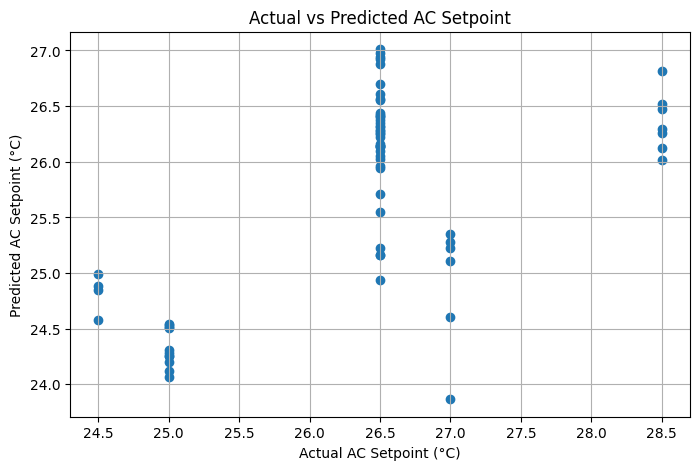

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual AC Setpoint (°C)")
plt.ylabel("Predicted AC Setpoint (°C)")

plt.title("Actual vs Predicted AC Setpoint")

plt.grid(True)
plt.show()

## 8. Download Trained Model

In [42]:
import joblib

# Save trained model
joblib.dump(model, "classroom_ac_model.pkl")

print("Model saved successfully!")

Model saved successfully!
